Keeping 2995 shared genes
Keeping 277 shared TFs
Loaded weights: (1035, 4), A_dict: (4, 2995, 277)
Using 10 sampled cells out of 1035

=== Sampled Cells vs Population-Average GRN ===
Mean average-per-TF top-10% Jaccard: 0.6672
Std: 0.1517
Min: 0.4225
Max: 0.8931

=== Sampled Cells vs CellOracle Global GRN ===
Mean average-per-TF top-10% Jaccard: 0.3932
Std: 0.0274
Min: 0.3478
Max: 0.4245

=== Our Global GRN vs CellOracle Global GRN ===
Average-per-TF top-10% Jaccard: 0.4215

=== Sampled Cell-Specific GRNs ===
Number of sampled pairwise comparisons: 45
Mean average-per-TF top-10% Jaccard: 0.5756
Std: 0.1407
Min: 0.4020
Max: 0.8805

=== Module vs Module Average-per-TF top-10% Jaccard ===
[[1.    0.408 0.398 0.393]
 [0.408 1.    0.375 0.379]
 [0.398 0.375 1.    0.4  ]
 [0.393 0.379 0.4   1.   ]]


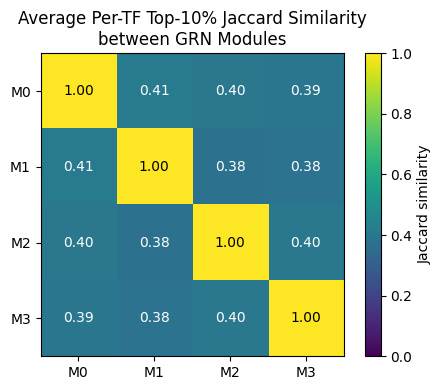

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
import pandas as pd

# ================================================================
# INSERT BASE DIRECTORY HERE
# ================================================================
BASE = "/home/elicanter/bert_grn_out_61_masking2"

# ================================================================
# METRIC CONFIG
# ================================================================
TOP_FRAC = 0.10   # X% -> compare the top 10% strongest edges per TF
EPS = 1e-6        # entries with |weight| <= EPS are treated as "no edge"

# ----------------------------------------------------------------
# Load your method's outputs
# ----------------------------------------------------------------
weights = np.load(f"{BASE}/run0/mix_weights.npy")      # (cells, D)
A_dict  = np.load(f"{BASE}/run0/A_dict.npy")           # (D, G, T)
A_genes = np.load(f"{BASE}/run0/A_genes.npy", allow_pickle=True).astype(str)
A_tfs   = np.load(f"{BASE}/run0/A_tfs.npy", allow_pickle=True).astype(str)


# ----------------------------------------------------------------
# Restrict to genes/TFs present in CellOracle outputs
# ----------------------------------------------------------------
CO_BASE = "/home/elicanter/cell_oracle_run"

co_genes = np.load(
    f"{CO_BASE}/cell_oracle_global_A/A_genes.npy",
    allow_pickle=True
).astype(str)

co_tfs = np.load(
    f"{CO_BASE}/cell_oracle_global_A/A_tfs.npy",
    allow_pickle=True
).astype(str)


# ----------------------------------------------------------------
# Restrict to shared genes/TFs in identical order
# ----------------------------------------------------------------
co_A = np.load(f"{CO_BASE}/cell_oracle_global_A/A_celloracle.npy")
co_A = np.abs(co_A.T)

common_genes = np.intersect1d(A_genes, co_genes)
common_tfs   = np.intersect1d(A_tfs, co_tfs)

print(f"Keeping {len(common_genes)} shared genes")
print(f"Keeping {len(common_tfs)} shared TFs")

a_gene_idx = pd.Index(A_genes).get_indexer(common_genes)
a_tf_idx   = pd.Index(A_tfs).get_indexer(common_tfs)

co_gene_idx = pd.Index(co_genes).get_indexer(common_genes)
co_tf_idx   = pd.Index(co_tfs).get_indexer(common_tfs)

# Restrict our dictionary
A_dict = A_dict[:, a_gene_idx][:, :, a_tf_idx]
A_genes = common_genes
A_tfs = common_tfs

# Restrict CellOracle global GRN
co_A = co_A[co_gene_idx][:, co_tf_idx]

assert co_A.shape == (len(A_genes), len(A_tfs))
assert A_dict.shape[1:] == co_A.shape


n_cells, D = weights.shape
G = len(A_genes)
T = len(A_tfs)

print(f"Loaded weights: {weights.shape}, A_dict: {A_dict.shape}")
assert A_dict.shape[0] == D


# ================================================================
# Helper: average per-TF top-X% Jaccard similarity between two GRNs
# ================================================================
def avg_per_tf_topk_jaccard(grn1, grn2, top_frac=TOP_FRAC, eps=EPS):
    """
    grn1, grn2: (G, T) matrices.

    For each TF (column) independently:
      1. Rank genes by edge magnitude |weight| within that TF.
      2. Take the top `top_frac` fraction of genes as that TF's "top set",
         where the fraction is measured against the full gene axis (G),
         but only genes with |weight| > eps are eligible. This prevents
         sparse columns from being padded with arbitrary zero-weight genes.
      3. Compute the Jaccard similarity |A n B| / |A u B| of the two top sets.

    Returns the mean Jaccard across TFs (columns whose top set is empty in
    either GRN are skipped). Range: [0, 1].
    """
    G_, T_ = grn1.shape
    k = max(1, int(round(top_frac * G_)))   # target top-set size (top X% of genes)

    tf_jacc = []
    for t in range(T_):
        x = np.abs(grn1[:, t])
        y = np.abs(grn2[:, t])

        # Eligible (nonzero) genes for each GRN in this TF
        nz_x = np.flatnonzero(x > eps)
        nz_y = np.flatnonzero(y > eps)

        # No edges for this TF in one of the GRNs -> undefined overlap, skip
        if len(nz_x) == 0 or len(nz_y) == 0:
            continue

        # Take up to k strongest edges from each GRN (capped at its nonzero count)
        kx = min(k, len(nz_x))
        ky = min(k, len(nz_y))

        top_x = set(nz_x[np.argsort(x[nz_x])[::-1][:kx]])
        top_y = set(nz_y[np.argsort(y[nz_y])[::-1][:ky]])

        union = top_x | top_y
        if len(union) == 0:
            continue

        inter = top_x & top_y
        tf_jacc.append(len(inter) / len(union))

    return np.mean(tf_jacc) if len(tf_jacc) > 0 else np.nan


PCT = int(round(TOP_FRAC * 100))  # for printing / titles


# ================================================================
# A) Cell-specific GRNs (sampled)
# ================================================================

# Efficient representative sampling
N_SAMPLE = min(10, n_cells)
rng = np.random.default_rng(0)
sample_idx = rng.choice(n_cells, size=N_SAMPLE, replace=False)

print(f"Using {N_SAMPLE} sampled cells out of {n_cells}")

# Construct sampled cell-specific GRNs
# Result: (N_SAMPLE, G, T)
cell_grns = np.einsum("sd,dgt->sgt", weights[sample_idx], A_dict)

# ----------------------------------------------------------------
# Population-average GRN
# ----------------------------------------------------------------
mean_weights = weights.mean(axis=0)          # (D,)
global_grn = np.einsum("d,dgt->gt", mean_weights, A_dict)   # (G, T)

# ================================================================
# Cell-specific GRNs vs population-average GRN
# ================================================================
global_corrs = np.array([
    avg_per_tf_topk_jaccard(grn, global_grn)
    for grn in cell_grns
])

print(f"\n=== Sampled Cells vs Population-Average GRN ===")
print(f"Mean average-per-TF top-{PCT}% Jaccard: {global_corrs.mean():.4f}")
print(f"Std: {global_corrs.std():.4f}")
print(f"Min: {global_corrs.min():.4f}")
print(f"Max: {global_corrs.max():.4f}")

# ================================================================
# Sampled Cells vs CellOracle Global GRN
# ================================================================
co_global_corrs = np.array([
    avg_per_tf_topk_jaccard(np.abs(grn), co_A)
    for grn in cell_grns
])

print(f"\n=== Sampled Cells vs CellOracle Global GRN ===")
print(f"Mean average-per-TF top-{PCT}% Jaccard: {co_global_corrs.mean():.4f}")
print(f"Std: {co_global_corrs.std():.4f}")
print(f"Min: {co_global_corrs.min():.4f}")
print(f"Max: {co_global_corrs.max():.4f}")

# ================================================================
# Our Global GRN vs CellOracle Global GRN
# ================================================================
global_vs_co = avg_per_tf_topk_jaccard(np.abs(global_grn), co_A)

print(f"\n=== Our Global GRN vs CellOracle Global GRN ===")
print(f"Average-per-TF top-{PCT}% Jaccard: {global_vs_co:.4f}")

# ================================================================
# Cell-specific GRNs vs each other (pairwise)
# ================================================================

pair_corrs = []
for i, j in combinations(range(N_SAMPLE), 2):
    c = avg_per_tf_topk_jaccard(cell_grns[i], cell_grns[j])
    if not np.isnan(c):
        pair_corrs.append(c)

pair_corrs = np.array(pair_corrs)

print(f"\n=== Sampled Cell-Specific GRNs ===")
print(f"Number of sampled pairwise comparisons: {len(pair_corrs)}")
print(f"Mean average-per-TF top-{PCT}% Jaccard: {pair_corrs.mean():.4f}")
print(f"Std: {pair_corrs.std():.4f}")
print(f"Min: {pair_corrs.min():.4f}")
print(f"Max: {pair_corrs.max():.4f}")


# ================================================================
# B) GRN modules themselves (all D x D pairs)
# ================================================================
module_corr = np.eye(D)   # self-Jaccard = 1.0 on the diagonal

for i in range(D):
    for j in range(i + 1, D):
        c = avg_per_tf_topk_jaccard(A_dict[i], A_dict[j])
        module_corr[i, j] = c
        module_corr[j, i] = c

print(f"\n=== Module vs Module Average-per-TF top-{PCT}% Jaccard ===")
print(np.round(module_corr, 3))


# ================================================================
# Heatmap of module similarities
# ================================================================
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(module_corr, vmin=0, vmax=1, cmap="viridis")

ax.set_xticks(range(D))
ax.set_yticks(range(D))
ax.set_xticklabels([f"M{i}" for i in range(D)])
ax.set_yticklabels([f"M{i}" for i in range(D)])

for i in range(D):
    for j in range(D):
        val = module_corr[i, j]
        ax.text(j, i, f"{val:.2f}",
                ha="center", va="center",
                color="white" if val < 0.5 else "black")

ax.set_title(f"Average Per-TF Top-{PCT}% Jaccard Similarity\nbetween GRN Modules")
fig.colorbar(im, ax=ax, label="Jaccard similarity")
plt.tight_layout()
plt.show()

Genes: 2995, TFs: 277, cells: 1035, modules: 4

=== Top-X% Jaccard sweep ===
 X%  cells_vs_popavg  cell_cell_pairwise  cells_vs_CO  global_vs_CO  module_offdiag  null_within  null_cross
  1            0.404               0.275        0.059         0.075           0.203        0.003       0.003
  2            0.456               0.314        0.088         0.120           0.209        0.006       0.005
  5            0.516               0.378        0.140         0.184           0.180        0.013       0.013
 10            0.562               0.433        0.192         0.235           0.203        0.028       0.027
 20            0.604               0.486        0.257         0.298           0.254        0.057       0.056
 25            0.616               0.503        0.285         0.326           0.281        0.071       0.071

=== Fold over random floor ===
 X%  cells_vs_popavg  cell_cell_pairwise  module_offdiag  cells_vs_CO  global_vs_CO
  1          140.591              95.506    

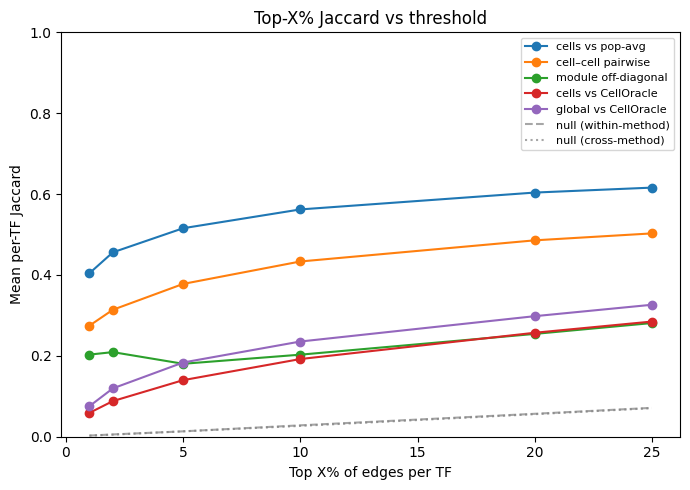

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
import pandas as pd

# ================================================================
# CONFIG
# ================================================================
BASE    = "/home/elicanter/bert_grn_out_61_masking2"
CO_BASE = "/home/elicanter/cell_oracle_run"
EPS = 1e-6
PERCENTAGES = [0.01, 0.02, 0.05, 0.10, 0.20, 0.25]   # X values to sweep
N_NULL = 5                                           # permutations per null estimate

# ================================================================
# Load + restrict to shared genes/TFs (identical to main pipeline)
# ================================================================
weights = np.load(f"{BASE}/run0/mix_weights.npy")
A_dict  = np.load(f"{BASE}/run0/A_dict.npy")
A_genes = np.load(f"{BASE}/run0/A_genes.npy", allow_pickle=True).astype(str)
A_tfs   = np.load(f"{BASE}/run0/A_tfs.npy", allow_pickle=True).astype(str)

co_genes = np.load(f"{CO_BASE}/cell_oracle_global_A/A_genes.npy", allow_pickle=True).astype(str)
co_tfs   = np.load(f"{CO_BASE}/cell_oracle_global_A/A_tfs.npy", allow_pickle=True).astype(str)
co_A     = np.abs(np.load(f"{CO_BASE}/cell_oracle_global_A/A_celloracle.npy").T)

common_genes = np.intersect1d(A_genes, co_genes)
common_tfs   = np.intersect1d(A_tfs, co_tfs)

a_gene_idx  = pd.Index(A_genes).get_indexer(common_genes)
a_tf_idx    = pd.Index(A_tfs).get_indexer(common_tfs)
co_gene_idx = pd.Index(co_genes).get_indexer(common_genes)
co_tf_idx   = pd.Index(co_tfs).get_indexer(common_tfs)

A_dict  = A_dict[:, a_gene_idx][:, :, a_tf_idx]
A_genes = common_genes
A_tfs   = common_tfs
co_A    = co_A[co_gene_idx][:, co_tf_idx]

n_cells, D = weights.shape
G, T = len(A_genes), len(A_tfs)
print(f"Genes: {G}, TFs: {T}, cells: {n_cells}, modules: {D}")


# ================================================================
# Metric + permutation null
# ================================================================
def avg_per_tf_topk_jaccard(grn1, grn2, top_frac, eps=EPS, denom="union"):
    """Mean over TFs of Jaccard between each GRN's top-`top_frac` strongest edges.

    top_frac is applied AFTER excluding shared zeros:
        denom = "union" : X% of genes nonzero in EITHER GRN for that TF
                          (matches shared-zero removal)  <-- default
        denom = "own"   : X% of each GRN's OWN nonzero edges (set sizes float)
        denom = "all"   : X% of all G genes (old behavior)
    A gene zero in both GRNs is never eligible for either top set regardless.
    """
    G_, T_ = grn1.shape
    j = []
    for t in range(T_):
        x = np.abs(grn1[:, t]); y = np.abs(grn2[:, t])
        nz_x = np.flatnonzero(x > eps); nz_y = np.flatnonzero(y > eps)
        if len(nz_x) == 0 or len(nz_y) == 0:
            continue

        if denom == "union":
            n_u = len(np.union1d(nz_x, nz_y))          # genes surviving shared-zero removal
            k = max(1, int(round(top_frac * n_u)))
            kx = min(k, len(nz_x)); ky = min(k, len(nz_y))
        elif denom == "own":
            kx = max(1, int(round(top_frac * len(nz_x))))
            ky = max(1, int(round(top_frac * len(nz_y))))
        elif denom == "all":
            k = max(1, int(round(top_frac * G_)))
            kx = min(k, len(nz_x)); ky = min(k, len(nz_y))
        else:
            raise ValueError(f"unknown denom: {denom}")

        tx = set(nz_x[np.argsort(x[nz_x])[::-1][:kx]])
        ty = set(nz_y[np.argsort(y[nz_y])[::-1][:ky]])
        u = tx | ty
        if u:
            j.append(len(tx & ty) / len(u))
    return np.mean(j) if j else np.nan


def null_jaccard(grn1, grn2, top_frac, n=N_NULL, seed=0):
    """Random floor: shuffle grn2's gene axis, destroying cross-GRN gene correspondence
    while preserving each GRN's per-TF magnitude distribution."""
    rng = np.random.default_rng(seed)
    vals = [avg_per_tf_topk_jaccard(grn1, grn2[rng.permutation(grn2.shape[0])], top_frac)
            for _ in range(n)]
    return np.nanmean(vals)


# ================================================================
# Build GRNs (same sample as the main pipeline: default_rng(0))
# ================================================================
N_SAMPLE = min(10, n_cells)
sample_idx = np.random.default_rng(0).choice(n_cells, size=N_SAMPLE, replace=False)
cell_grns  = np.einsum("sd,dgt->sgt", weights[sample_idx], A_dict)      # (N_SAMPLE, G, T)
global_grn = np.einsum("d,dgt->gt", weights.mean(axis=0), A_dict)       # (G, T)


# ================================================================
# Sweep X
# ================================================================
rows = []
for tf in PERCENTAGES:
    cvp  = np.mean([avg_per_tf_topk_jaccard(g, global_grn, tf) for g in cell_grns])
    pw   = np.mean([avg_per_tf_topk_jaccard(cell_grns[i], cell_grns[j], tf)
                    for i, j in combinations(range(N_SAMPLE), 2)])
    cvco = np.mean([avg_per_tf_topk_jaccard(np.abs(g), co_A, tf) for g in cell_grns])
    gvco = avg_per_tf_topk_jaccard(np.abs(global_grn), co_A, tf)
    mod  = np.mean([avg_per_tf_topk_jaccard(A_dict[i], A_dict[j], tf)
                    for i, j in combinations(range(D), 2)])

    # Two null regimes, since sparsity differs within- vs cross-method
    null_within = null_jaccard(A_dict[0], A_dict[1], tf)          # module vs module
    null_cross  = null_jaccard(np.abs(global_grn), co_A, tf)      # ours vs CellOracle

    rows.append((int(round(tf * 100)), cvp, pw, cvco, gvco, mod, null_within, null_cross))

df = pd.DataFrame(rows, columns=[
    "X%", "cells_vs_popavg", "cell_cell_pairwise",
    "cells_vs_CO", "global_vs_CO", "module_offdiag",
    "null_within", "null_cross",
])

pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print("\n=== Top-X% Jaccard sweep ===")
print(df.to_string(index=False))

# Signal-over-null (how far above the random floor each comparison sits)
print("\n=== Fold over random floor ===")
fold = df.copy()
fold["cells_vs_popavg"]    = df["cells_vs_popavg"]    / df["null_within"]
fold["cell_cell_pairwise"] = df["cell_cell_pairwise"] / df["null_within"]
fold["module_offdiag"]     = df["module_offdiag"]     / df["null_within"]
fold["cells_vs_CO"]        = df["cells_vs_CO"]        / df["null_cross"]
fold["global_vs_CO"]       = df["global_vs_CO"]       / df["null_cross"]
print(fold[["X%", "cells_vs_popavg", "cell_cell_pairwise",
            "module_offdiag", "cells_vs_CO", "global_vs_CO"]].to_string(index=False))


# ================================================================
# Plot Jaccard vs X, with null floors
# ================================================================
x = df["X%"]
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, df["cells_vs_popavg"],    "-o", label="cells vs pop-avg")
ax.plot(x, df["cell_cell_pairwise"], "-o", label="cell–cell pairwise")
ax.plot(x, df["module_offdiag"],     "-o", label="module off-diagonal")
ax.plot(x, df["cells_vs_CO"],        "-o", label="cells vs CellOracle")
ax.plot(x, df["global_vs_CO"],       "-o", label="global vs CellOracle")
ax.plot(x, df["null_within"], "--", color="grey", alpha=0.7, label="null (within-method)")
ax.plot(x, df["null_cross"],  ":",  color="grey", alpha=0.7, label="null (cross-method)")

ax.set_xlabel("Top X% of edges per TF")
ax.set_ylabel("Mean per-TF Jaccard")
ax.set_title("Top-X% Jaccard vs threshold")
ax.set_ylim(0, 1)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("jaccard_sweep.png", dpi=150)
plt.show()

Mean per-TF top-10% Jaccard: 0.2354343193692005

--- Hub TF comparison ---
Hub TF agreement (Spearman): rho=0.8838


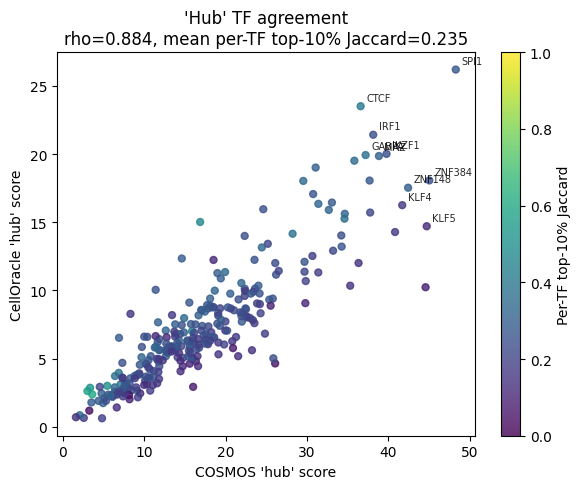

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

TOP_FRAC = 0.10        # top 10% strongest edges per TF
EPS = 1e-6

# ================================================================
# Per-TF top-X% Jaccard scores (one value per TF)
# ================================================================
def per_tf_topk_jaccard(grn1, grn2, top_frac=0.10, eps=1e-6, denom="union"):
    """
    denom = "union" : 10% of genes nonzero in EITHER GRN (matches your shared-zero
                       removal philosophy)  <-- recommended
    denom = "own"   : 10% of each GRN's OWN nonzero edges (set sizes float per GRN)
    denom = "all"   : 10% of all G genes (what the earlier code did)
    """
    G_, T_ = grn1.shape
    out = np.full(T_, np.nan)
    for t in range(T_):
        x = np.abs(grn1[:, t]); y = np.abs(grn2[:, t])
        nz_x = np.flatnonzero(x > eps); nz_y = np.flatnonzero(y > eps)
        if len(nz_x) == 0 or len(nz_y) == 0:
            continue
        if denom == "all":
            k = max(1, round(top_frac * G_)); kx = min(k, len(nz_x)); ky = min(k, len(nz_y))
        elif denom == "union":
            n_u = len(np.union1d(nz_x, nz_y))            # survives shared-zero removal
            k = max(1, round(top_frac * n_u)); kx = min(k, len(nz_x)); ky = min(k, len(nz_y))
        elif denom == "own":
            kx = max(1, round(top_frac * len(nz_x))); ky = max(1, round(top_frac * len(nz_y)))
        tx = set(nz_x[np.argsort(x[nz_x])[::-1][:kx]])
        ty = set(nz_y[np.argsort(y[nz_y])[::-1][:ky]])
        u = tx | ty
        out[t] = len(tx & ty) / len(u) if u else np.nan
    return out

# ================================================================
# Compare two GRNs
# ================================================================
A_pred_shared = global_grn
A_co_shared   = co_A

tf_jacc = per_tf_topk_jaccard(A_pred_shared, A_co_shared, TOP_FRAC)
pct = int(round(TOP_FRAC * 100))
print(f"Mean per-TF top-{pct}% Jaccard:", np.nanmean(tf_jacc))

# ================================================================
# Hub TF scores (unchanged — magnitude agreement across TFs)
# ================================================================
hub_pred = np.abs(A_pred_shared).sum(axis=0)
hub_co   = np.abs(A_co_shared).sum(axis=0)
hub_rho, _ = spearmanr(hub_pred, hub_co)
print("\n--- Hub TF comparison ---")
print(f"Hub TF agreement (Spearman): rho={hub_rho:.4f}")

# ================================================================
# Hub TF scatter colored by per-TF top-X% Jaccard
# ================================================================
cmap = plt.cm.viridis.copy()
cmap.set_bad("lightgrey")   # TFs with no comparable edges

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(
    hub_pred,
    hub_co,
    c=tf_jacc,
    cmap=cmap,
    vmin=0,
    vmax=1,          # tighten to np.nanmax(tf_jacc) for more contrast if desired
    s=25,
    alpha=0.8
)

# Label top TFs by combined hub score
top10_idx = np.argsort(hub_pred + hub_co)[-10:]
for ti in top10_idx:
    ax.annotate(
        A_tfs[ti],
        (hub_pred[ti], hub_co[ti]),
        fontsize=7,
        alpha=0.85,
        xytext=(4, 4),
        textcoords="offset points"
    )

ax.set_xlabel("COSMOS 'hub' score")
ax.set_ylabel("CellOracle 'hub' score")
ax.set_title(
    f"'Hub' TF agreement\n"
    f"rho={hub_rho:.3f}, mean per-TF top-{pct}% Jaccard={np.nanmean(tf_jacc):.3f}"
)
fig.colorbar(sc, ax=ax, label=f"Per-TF top-{pct}% Jaccard")
plt.tight_layout()
plt.show()

In [15]:
# ================================================================
# Load CellOracle cluster GRNs
# ================================================================
N_CLUSTERS = 9

cluster_As = [
    np.load(f"{CO_BASE}/A_clusters/A_cluster_{k}.npy")
    for k in range(N_CLUSTERS)
]

# CellOracle cluster GRNs are also TF x gene, so transpose
cluster_As = [np.abs(A.T) for A in cluster_As]

# Restrict to the same gene/TF universe
cluster_As = [
    A[co_gene_idx][:, co_tf_idx]
    for A in cluster_As
]

for k, A in enumerate(cluster_As):
    assert A.shape == (len(A_genes), len(A_tfs)), (
        f"Cluster {k} has shape {A.shape}, expected {(len(A_genes), len(A_tfs))}"
    )

print(f"Loaded {len(cluster_As)} CellOracle cluster GRNs")
print(f"Each cluster GRN shape: {cluster_As[0].shape}")

clusters_raw = np.load(
    "/home/elicanter/cell_oracle_run/clusters_raw.npy",
    allow_pickle=True
)
clusters_raw = clusters_raw.astype(int)

Loaded 9 CellOracle cluster GRNs
Each cluster GRN shape: (2995, 277)


n_cells: 1035   clusters: 9
Accuracy (z-normalized):     0.233
Shuffle null:                0.079 ± 0.008
Nominal chance (1/K):        0.111
Empirical p vs shuffle:      < 0.0050
Mean own-cluster rank:       2.97 of 9 (null 5.0)
Own cluster is best match:   0.233   top-3: 0.712
Mean own-cluster z:          +0.309  (Wilcoxon own_z > 0: p=8.89e-54)


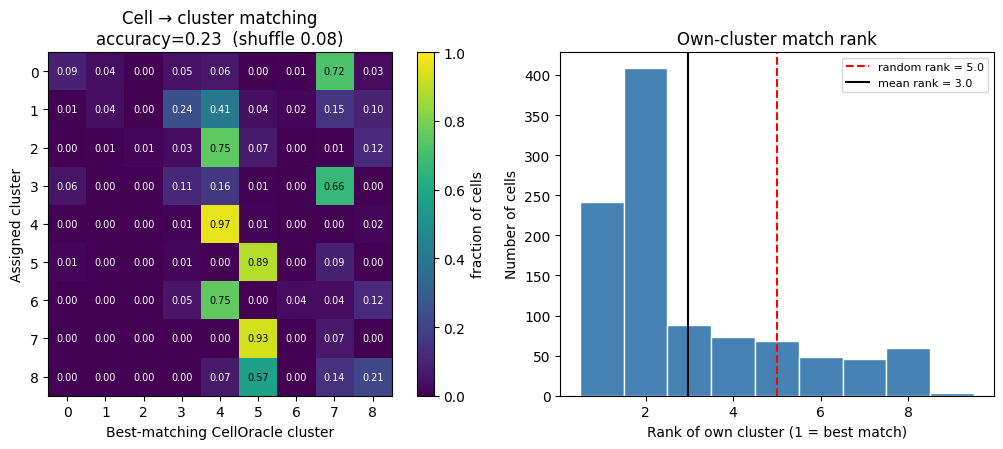

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

# ================================================================
# Assumes these are already in scope from your pipeline:
#   weights       (n_cells, D)
#   A_dict        (D, G, T)
#   cluster_As    list of (G, T) CellOracle cluster GRNs (aligned genes/TFs)
#   clusters_raw  (n_cells,) CellOracle cluster label per cell
# ================================================================
TOP_FRAC = 0.10
EPS = 1e-6
N_SHUFFLE = 200
SEED = 0

clusters_raw = clusters_raw.astype(int)
N_CLUSTERS = len(cluster_As)
G, T = cluster_As[0].shape


# ----------------------------------------------------------------
# Precompute, per GRN: for each TF, its nonzero gene indices sorted
# by descending magnitude, plus a boolean nonzero mask.
# ----------------------------------------------------------------
def precompute_orders(grn_abs, eps=EPS):
    orders = []
    mask = np.zeros((T, G), dtype=bool)
    for t in range(T):
        x = grn_abs[:, t]
        nz = np.flatnonzero(x > eps)
        orders.append(nz[np.argsort(x[nz])[::-1]])
        mask[t, nz] = True
    return orders, mask


# CellOracle cluster side: computed ONCE (doesn't change per cell)
cl_orders, cl_mask = [], []
for m in range(N_CLUSTERS):
    o, mm = precompute_orders(np.abs(cluster_As[m]))
    cl_orders.append(o)
    cl_mask.append(mm)


def mean_jaccard(cell_orders, m, top_frac=TOP_FRAC):
    """Mean per-TF top-X% Jaccard between one cell and cluster m.
    'Top X%' is taken over genes nonzero in EITHER GRN (union denominator)."""
    j = []
    for t in range(T):
        ox = cell_orders[t]
        oy = cl_orders[m][t]
        if ox.size == 0 or oy.size == 0:
            continue
        overlap_nz = cl_mask[m][t][ox].sum()            # |nz_cell ∩ nz_cluster|
        union_nz = ox.size + oy.size - overlap_nz
        k = max(1, int(round(top_frac * union_nz)))
        kx = min(k, ox.size)
        ky = min(k, oy.size)
        inter = np.intersect1d(ox[:kx], oy[:ky], assume_unique=True).size
        j.append(inter / (kx + ky - inter))
    return np.mean(j) if j else np.nan


# ----------------------------------------------------------------
# Score every cell against every cluster (stream one cell at a time)
# ----------------------------------------------------------------
assigned, J_rows = [], []
for cidx in range(weights.shape[0]):
    cell_grn = np.abs(np.einsum("d,dgt->gt", weights[cidx], A_dict))
    cell_orders, _ = precompute_orders(cell_grn)
    J_rows.append([mean_jaccard(cell_orders, m) for m in range(N_CLUSTERS)])
    assigned.append(clusters_raw[cidx])

assigned = np.array(assigned)
J = np.array(J_rows)                                   # (n_cells, N_CLUSTERS), raw Jaccard


# ----------------------------------------------------------------
# z-normalize each cluster column (removes cluster size/density bias)
# ----------------------------------------------------------------
Z = (J - np.nanmean(J, axis=0, keepdims=True)) / np.nanstd(J, axis=0, keepdims=True)
Z_filled = np.where(np.isnan(Z), -np.inf, Z)
predicted = Z_filled.argmax(1)


# ----------------------------------------------------------------
# Accuracy vs the correct (shuffle) null
# ----------------------------------------------------------------
acc = (predicted == assigned).mean()
rng = np.random.default_rng(SEED)
shuffle_acc = np.array([(predicted == rng.permutation(assigned)).mean()
                        for _ in range(N_SHUFFLE)])
p_emp = (shuffle_acc >= acc).mean()

# Own-cluster rank per cell (1 = own cluster is the best match). No max-of-k bias.
own_z = Z[np.arange(len(Z)), assigned]
ranks = (Z > own_z[:, None]).sum(1) + 1

print(f"n_cells: {len(J)}   clusters: {N_CLUSTERS}")
print(f"Accuracy (z-normalized):     {acc:.3f}")
print(f"Shuffle null:                {shuffle_acc.mean():.3f} ± {shuffle_acc.std():.3f}")
print(f"Nominal chance (1/K):        {1/N_CLUSTERS:.3f}")
print(f"Empirical p vs shuffle:      {'< %.4f' % (1/N_SHUFFLE) if p_emp == 0 else '%.4f' % p_emp}")
print(f"Mean own-cluster rank:       {ranks.mean():.2f} of {N_CLUSTERS} "
      f"(null {(N_CLUSTERS+1)/2:.1f})")
print(f"Own cluster is best match:   {(ranks==1).mean():.3f}   top-3: {(ranks<=3).mean():.3f}")
print(f"Mean own-cluster z:          {own_z.mean():+.3f}  "
      f"(Wilcoxon own_z > 0: p={wilcoxon(own_z).pvalue:.2e})")


# ----------------------------------------------------------------
# Figure: confusion matrix + own-cluster rank histogram
# ----------------------------------------------------------------
conf = np.zeros((N_CLUSTERS, N_CLUSTERS))
for a, pr in zip(assigned, predicted):
    conf[a, pr] += 1
conf = conf / conf.sum(axis=1, keepdims=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6),
                               gridspec_kw={"width_ratios": [1.15, 1]})

im = ax1.imshow(conf, vmin=0, vmax=1, cmap="viridis")
for a in range(N_CLUSTERS):
    for b in range(N_CLUSTERS):
        ax1.text(b, a, f"{conf[a, b]:.2f}", ha="center", va="center",
                 color="white" if conf[a, b] < 0.5 else "black", fontsize=7)
ax1.set_xlabel("Best-matching CellOracle cluster")
ax1.set_ylabel("Assigned cluster")
ax1.set_xticks(range(N_CLUSTERS)); ax1.set_yticks(range(N_CLUSTERS))
ax1.set_title(f"Cell → cluster matching\naccuracy={acc:.2f}  (shuffle {shuffle_acc.mean():.2f})")
fig.colorbar(im, ax=ax1, label="fraction of cells", fraction=0.046)

ax2.hist(ranks, bins=np.arange(1, N_CLUSTERS + 2) - 0.5,
         color="steelblue", edgecolor="white")
ax2.axvline((N_CLUSTERS + 1) / 2, color="red", ls="--",
            label=f"random rank = {(N_CLUSTERS+1)/2:.1f}")
ax2.axvline(ranks.mean(), color="black", ls="-",
            label=f"mean rank = {ranks.mean():.1f}")
ax2.set_xlabel("Rank of own cluster (1 = best match)")
ax2.set_ylabel("Number of cells")
ax2.set_title("Own-cluster match rank")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig("cluster_discrimination.png", dpi=150)
plt.show()

In [23]:
sizes = np.bincount(assigned, minlength=N_CLUSTERS)
for k in range(N_CLUSTERS):
    sel = assigned == k
    recall = (predicted[sel] == k).mean() if sizes[k] else np.nan
    mrank  = ranks[sel].mean() if sizes[k] else np.nan
    won    = (predicted == k).mean()   # how often cluster k is anyone's best match
    print(f"cluster {k}: n={sizes[k]:4d}  recall={recall:.2f}  "
          f"mean_own_rank={mrank:.1f}  predicted_share={won:.2f}")

cluster 0: n= 310  recall=0.09  mean_own_rank=2.8  predicted_share=0.04
cluster 1: n= 165  recall=0.04  mean_own_rank=5.0  predicted_share=0.02
cluster 2: n= 141  recall=0.01  mean_own_rank=2.6  predicted_share=0.00
cluster 3: n= 137  recall=0.11  mean_own_rank=3.6  predicted_share=0.08
cluster 4: n= 115  recall=0.97  mean_own_rank=1.1  predicted_share=0.36
cluster 5: n=  81  recall=0.89  mean_own_rank=1.2  predicted_share=0.11
cluster 6: n=  57  recall=0.04  mean_own_rank=3.9  predicted_share=0.01
cluster 7: n=  15  recall=0.07  mean_own_rank=1.9  predicted_share=0.34
cluster 8: n=  14  recall=0.21  mean_own_rank=2.7  predicted_share=0.05
